In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json

import matplotlib.pyplot as plt
import numpy as np
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design()  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## confidence-histogram

**Figure 1: Distribution of the model's confidence on correct and incorrect answers.** Each histogram is normalized to unit area, since there are 1,800 correct and 420 incorrect answers. Correct answers concentrate at high confidence (median 0.85), while incorrect ones spread across the range (median 0.61), with 35% below 0.5 against 1% of correct answers.

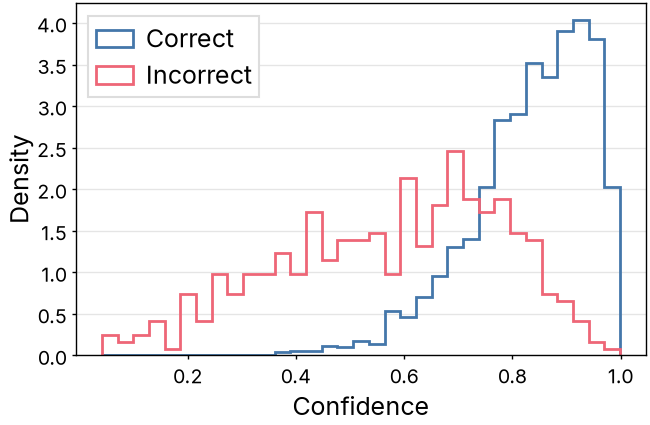

In [2]:
with open("../confidence-histogram.json") as f:
    data = json.load(f)

bins = np.histogram_bin_edges(np.concatenate([data["correct"], data["incorrect"]]), bins="auto")

fig, ax = plt.subplots(figsize=(3.25, 2))
ax.hist(data["correct"], bins=bins, density=True, histtype="step", linewidth=1, color=colors["series-1"], label="Correct")
ax.hist(data["incorrect"], bins=bins, density=True, histtype="step", linewidth=1, color=colors["series-2"], label="Incorrect")
ax.grid(axis="x", visible=False)
ax.set_xticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_xlabel("Confidence")
ax.set_ylabel("Density")
ax.legend(loc="upper left")

fit_height(fig, ax, aspect=0.618)
fig.savefig("confidence-histogram.pdf")
fig.savefig("confidence-histogram.png")
plt.show()